# 1. Загрузка и проверка данных

In [1]:
import pandas as pd
from sklearn.datasets import load_iris

In [2]:
iris = load_iris()
df = pd.DataFrame(iris.data, columns = iris.feature_names)
original_labels = iris.target
display(df.head())

,sepal length (cm),sepal width (cm),petal length (cm),petal width (cm)
0,5.1,3.5,1.4,0.2
1,4.9,3.0,1.4,0.2
2,4.7,3.2,1.3,0.2
3,4.6,3.1,1.5,0.2
4,5.0,3.6,1.4,0.2


In [3]:
display("Размерность выборки:",df.shape)
display("Пропущенные значения:", df.isnull().sum())

'Размерность выборки:'

(150, 4)

'Пропущенные значения:'

sepal length (cm)    0
sepal width (cm)     0
petal length (cm)    0
petal width (cm)     0
dtype: int64

# 2. Корреляционная матрица

,sepal length (cm),sepal width (cm),petal length (cm),petal width (cm)
sepal length (cm),1.000,-0.118,0.872,0.818
sepal width (cm),-0.118,1.000,-0.428,-0.366
petal length (cm),0.872,-0.428,1.000,0.963
petal width (cm),0.818,-0.366,0.963,1.000


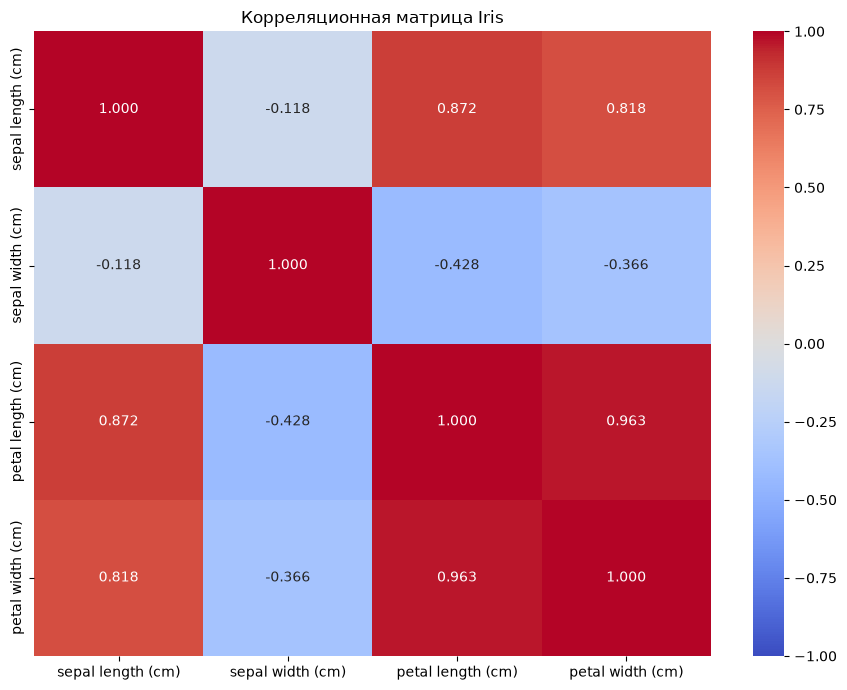

In [4]:
import matplotlib.pyplot as plt
import seaborn as sns
from pathlib import Path

pics_save = Path("../Pics/Iris")
pics_save.mkdir(parents=True, exist_ok=True)

corr_matrix = df.corr(method="pearson")

display(corr_matrix.round(3))

fig, ax = plt.subplots(figsize=(9, 7))
sns.heatmap(corr_matrix, annot=True, fmt=".3f", cmap="coolwarm", vmin=-1, vmax = 1, center=0,ax=ax)

ax.set_title("Корреляционная матрица Iris")
plt.tight_layout()

fig.savefig(pics_save/"1_correlation_matrix.png", dpi=300, bbox_inches="tight")
plt.show()

# 3. Трёхмерная визуализация Iris

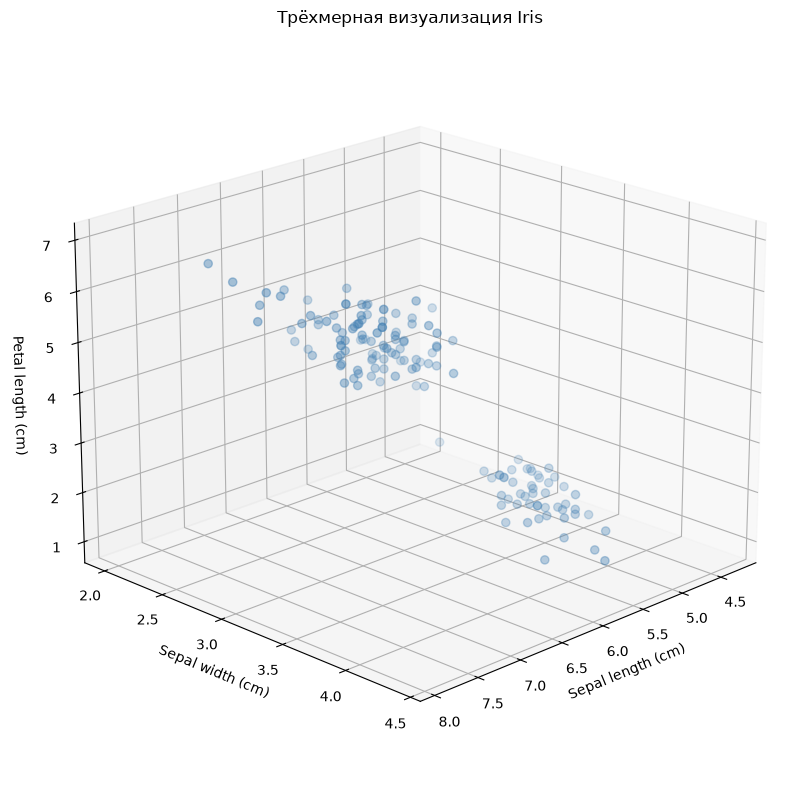

In [5]:
fig = plt.figure(figsize=(10, 8))
ax = fig.add_subplot(111, projection="3d")

ax.scatter(df["sepal length (cm)"], df["sepal width (cm)"],df["petal length (cm)"],color="steelblue",s=35, alpha=0.75)

ax.set_xlabel("Sepal length (cm)")
ax.set_ylabel("Sepal width (cm)")
ax.set_zlabel("Petal length (cm)")

ax.set_title("Трёхмерная визуализация Iris")

ax.view_init(elev=20, azim=45)

plt.tight_layout()

fig.savefig(pics_save / "1_iris_3d.png",dpi=300,bbox_inches="tight")

plt.show()

# 4. Стандартизация данных

In [6]:
from sklearn.preprocessing import StandardScaler

scaler = StandardScaler() #объект стандартизатора

X_scaled = scaler.fit_transform(df) #стандартизация всех четырёх признаков Iris

print("Размерность:", X_scaled.shape)
print("Средние значения:")
print(X_scaled.mean(axis=0).round(3))
print("Стандартные отклонения:")
print(X_scaled.std(axis=0).round(3))

Размерность: (150, 4)
Средние значения:
[-0. -0. -0. -0.]
Стандартные отклонения:
[1. 1. 1. 1.]


# 5. Иерархическая кластеризация

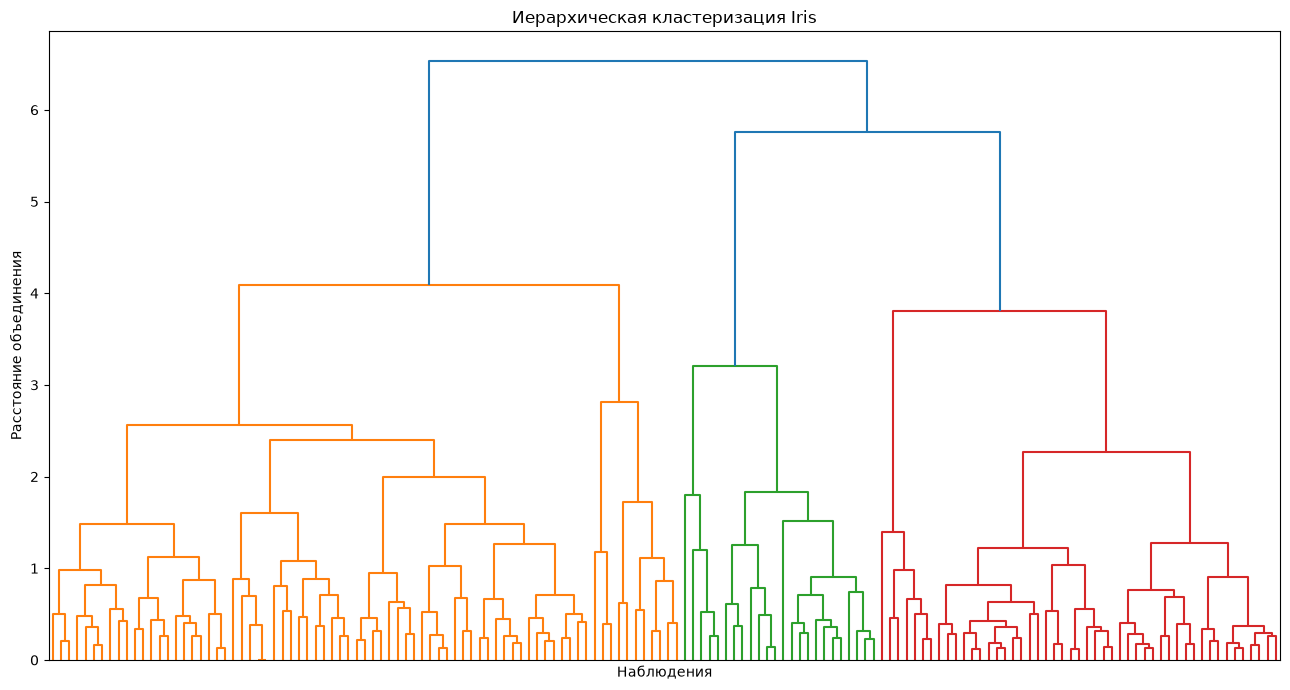

In [7]:
from scipy.cluster.hierarchy import linkage, dendrogram

Z = linkage(X_scaled,method="complete", metric="euclidean") #кластеризация методом полной связи с использованием евклидова расстояния

fig, ax = plt.subplots(figsize=(13, 7))

dendrogram(Z,ax=ax,no_labels=True)
ax.set_title("Иерархическая кластеризация Iris")
ax.set_xlabel("Наблюдения")
ax.set_ylabel("Расстояние объединения")

plt.tight_layout()

fig.savefig(pics_save / "2_dendrogram_complete.png",dpi=300,bbox_inches="tight")

plt.show()

In [8]:
from scipy.cluster.hierarchy import fcluster

labels_complete = fcluster(Z,t=4.5,criterion="distance")

print("Число кластеров:", len(set(labels_complete)))
print(pd.Series(labels_complete).value_counts().sort_index())

Число кластеров: 3
1    77
2    24
3    49
Name: count, dtype: int64


In [9]:
from scipy.cluster.hierarchy import linkage, dendrogram
import matplotlib.pyplot as plt

metrics = {"Евклидово": "euclidean","Манхэттенское": "cityblock","Чебышёва": "chebyshev","Косинусное": "cosine"} 
methods = {"Одиночная": "single","Полная": "complete", "Средняя": "average","Центроидная": "centroid","Уорда": "ward"}
results = {}

for metric_name, metric in metrics.items(): # проверка всех допустимых комбинаций
    for method_name, method in methods.items():
        if method in ["centroid", "ward"] and metric != "euclidean":
            continue
        Z_current = linkage(X_scaled, method=method,metric=metric) #иерархическая кластеризация
        results[(metric_name, method_name)] = Z_current # 

print("Количество комбинаций:", len(results))

Количество комбинаций: 14


In [ ]:
import numpy as np
from scipy.cluster.hierarchy import fcluster
from sklearn.metrics import adjusted_rand_score
# результаты всех методов
hierarchical_comparison = []
for (metric_name, method_name), Z_current in results.items():

    # Выделяем не более трёх кластеров
    labels = fcluster(Z_current,t=3, criterion="maxclust")
    sizes = sorted(np.unique(labels, return_counts=True)[1]) # размеры кластеров
    ari = adjusted_rand_score(iris.target,labels) # Сравнение кластеры с исходными видами Iris
    hierarchical_comparison.append({ "Метрика": metric_name, "Метод": method_name, "Размеры кластеров": str(sizes), "ARI": ari}) 

# таблица, отсортированную по ARI
hierarchical_df = pd.DataFrame(hierarchical_comparison)
display(hierarchical_df.sort_values("ARI", ascending=False ).round(3)
)

,Метрика,Метод,Размеры кластеров,ARI
7,Манхэттенское,Средняя,"[np.int64(35), np.int64(50), np.int64(65)]",0.718
12,Косинусное,Полная,"[np.int64(32), np.int64(49), np.int64(69)]",0.633
4,Евклидово,Уорда,"[np.int64(30), np.int64(49), np.int64(71)]",0.615
6,Манхэттенское,Полная,"[np.int64(27), np.int64(50), np.int64(73)]",0.615
13,Косинусное,Средняя,"[np.int64(27), np.int64(49), np.int64(74)]",0.610
1,Евклидово,Полная,"[np.int64(24), np.int64(49), np.int64(77)]",0.573
5,Манхэттенское,Одиночная,"[np.int64(2), np.int64(50), np.int64(98)]",0.564
3,Евклидово,Центроидная,"[np.int64(3), np.int64(50), np.int64(97)]",0.562
2,Евклидово,Средняя,"[np.int64(3), np.int64(50), np.int64(97)]",0.562
0,Евклидово,Одиночная,"[np.int64(1), np.int64(49), np.int64(100)]",0.558


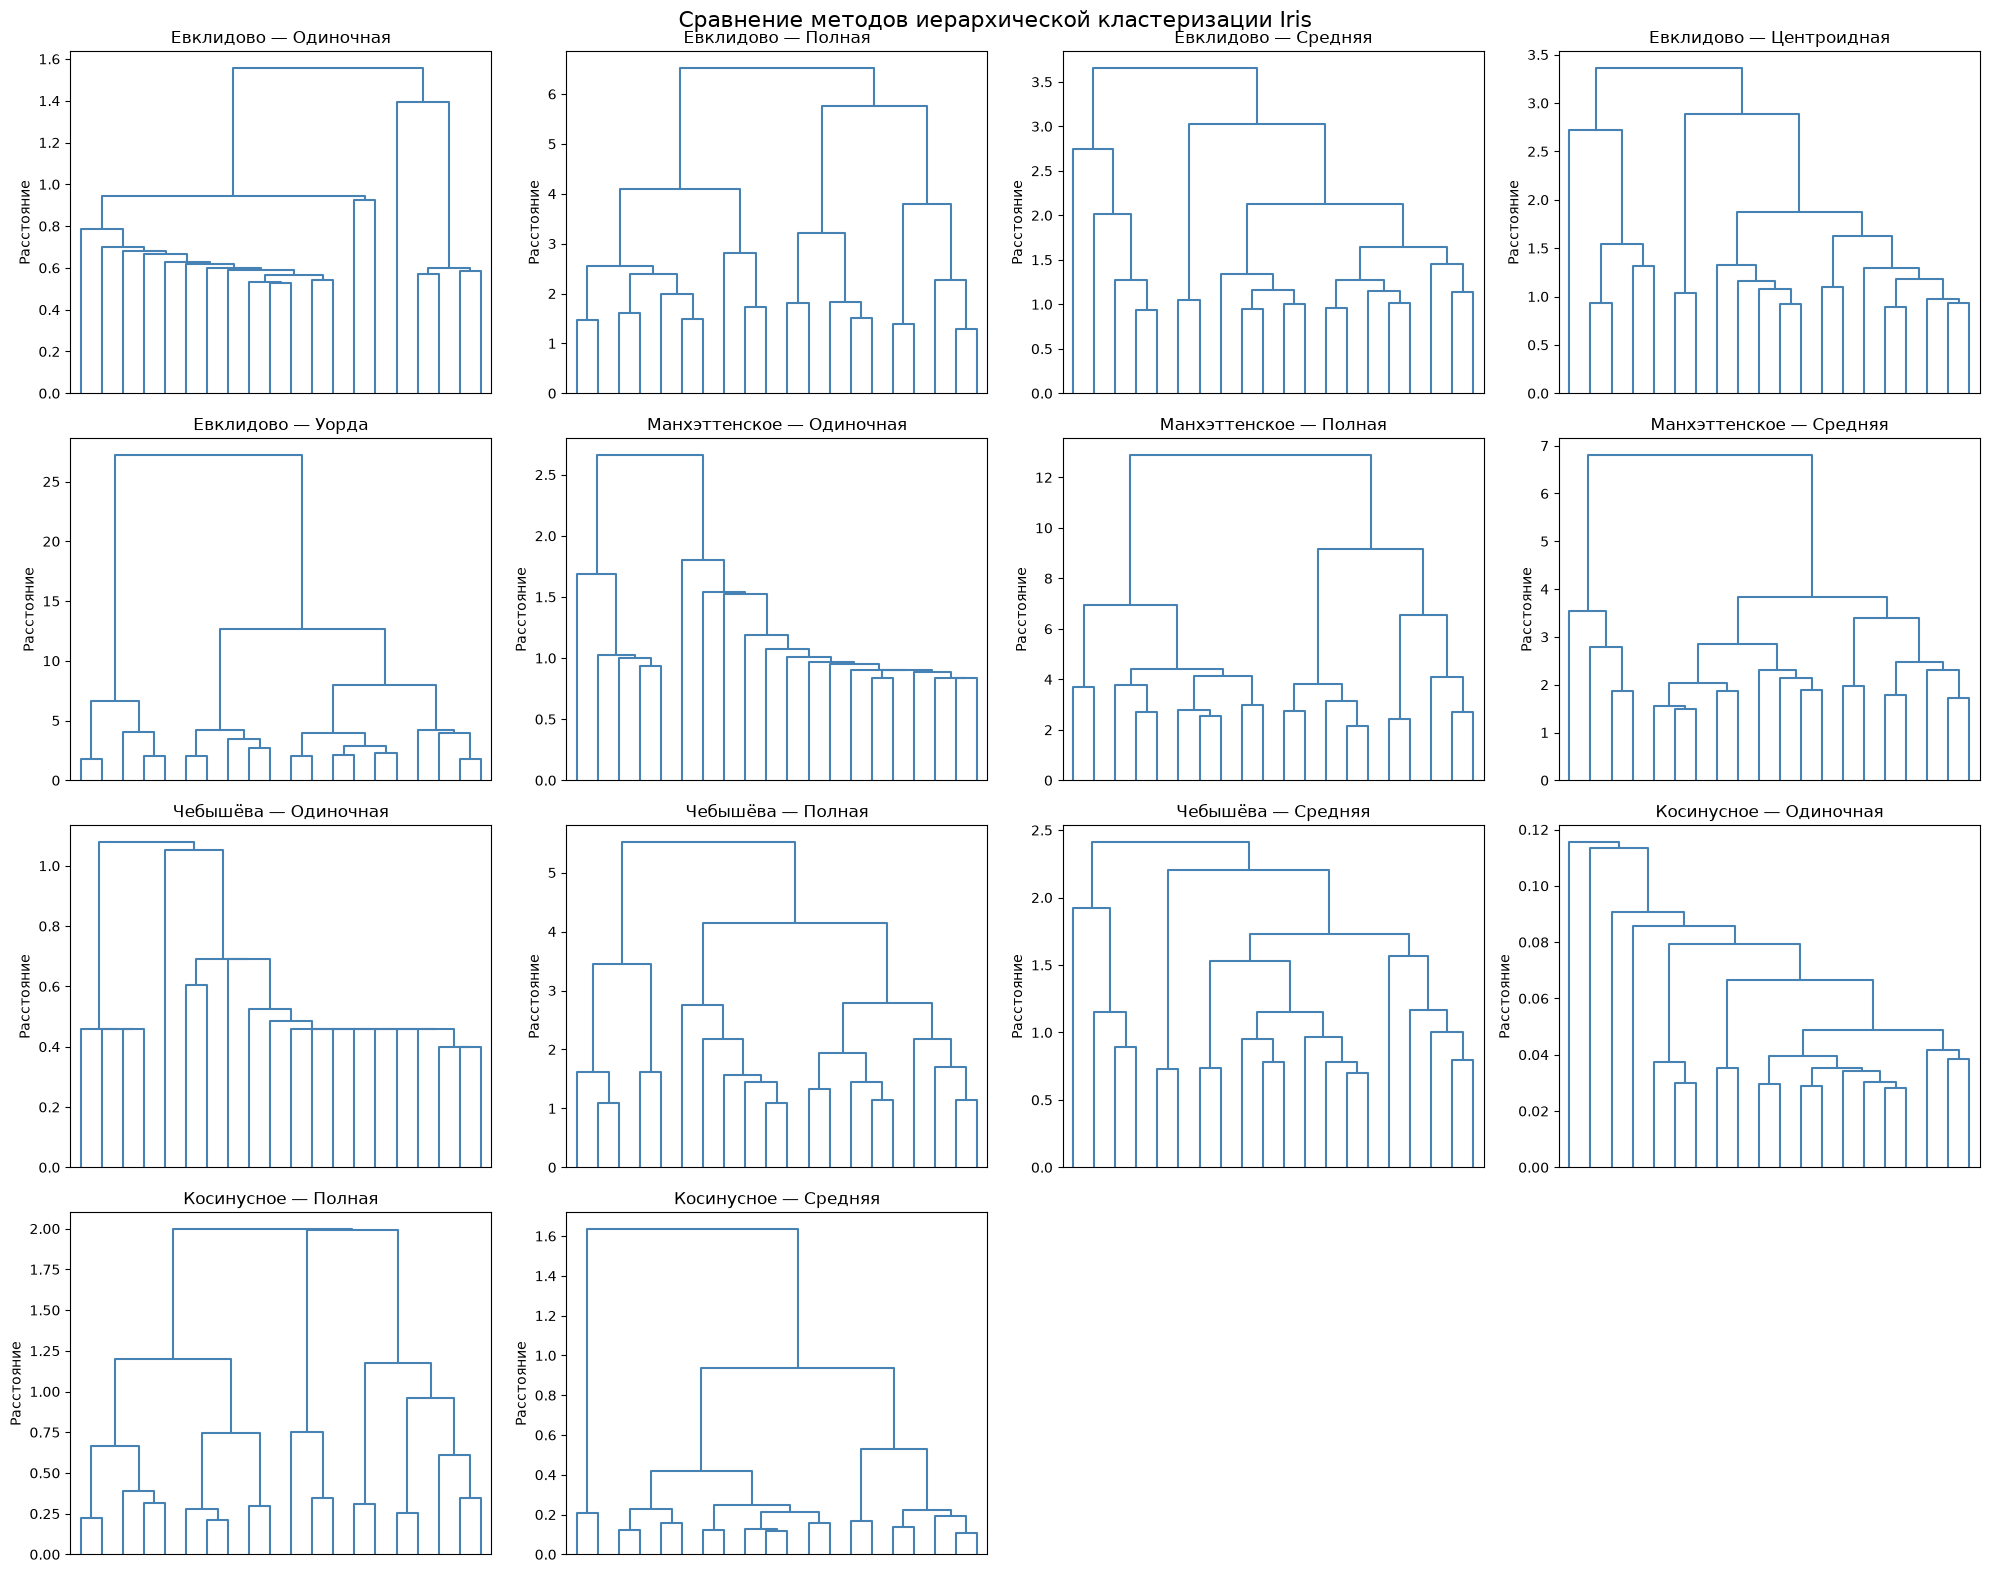

In [11]:
fig, axes = plt.subplots(4, 4,figsize=(20, 16))

axes = axes.flatten() # преобразование двумерного массива в одномерный

for ax, ((metric_name, method_name), Z_current) in zip(axes, results.items()): # дендрограммы для всех сохранённых комбинаций
    dendrogram(Z_current,truncate_mode="lastp", p=20, no_labels=True, color_threshold=0, above_threshold_color="steelblue", ax=ax)
    ax.set_title(f"{metric_name} — {method_name}")
    ax.set_ylabel("Расстояние")

for ax in axes[len(results):]: #Скрытие незаполненные области сетки
    ax.axis("off")

fig.suptitle( "Сравнение методов иерархической кластеризации Iris",fontsize=16)
plt.tight_layout()
fig.savefig(pics_save / "2_2_hierarchical_comparison.png",dpi=300,bbox_inches="tight")
plt.show()

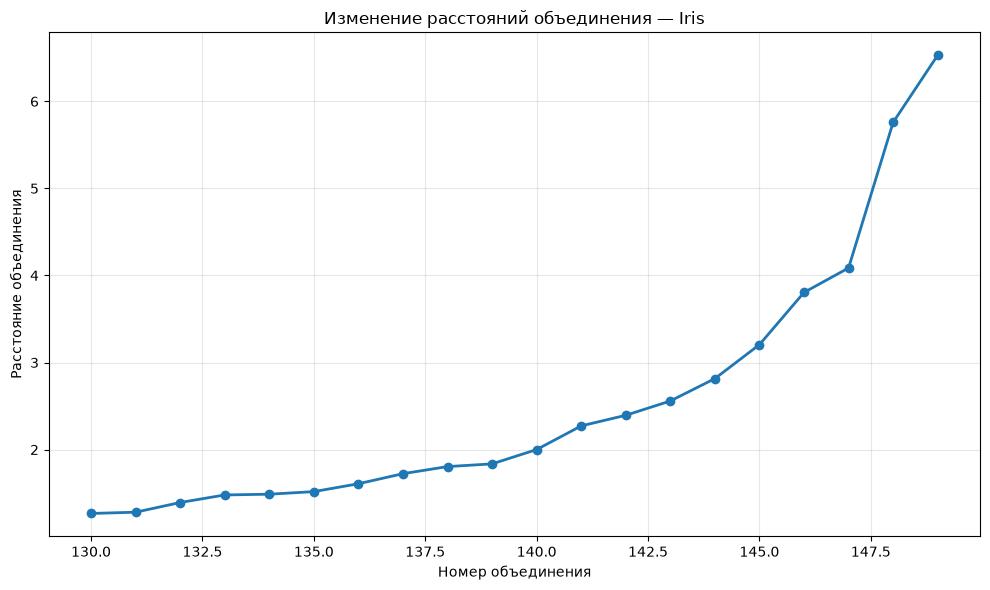

,Номер объединения,Расстояние
139,140,2.000
140,141,2.272
141,142,2.394
142,143,2.558
143,144,2.815
144,145,3.205
145,146,3.805
146,147,4.086
147,148,5.758
148,149,6.529


In [12]:
import numpy as np

Z_complete = results[("Евклидово", "Полная")] # Получение результата кластеризации методом полной связи с евклидовым расстоянием
distances = Z_complete[:, 2] # # Извлечение расстояния, при которых происходили объединения
n_last = 20 #  количество последних объединений для отображения

steps = np.arange(len(distances) - n_last + 1,len(distances) + 1) #номера последних объединений

fig, ax = plt.subplots(figsize=(10, 6))
ax.plot(steps,distances[-n_last:],marker="o",linewidth=2) # график с точками для каждого объединения

ax.set_title("Изменение расстояний объединения — Iris")
ax.set_xlabel("Номер объединения")
ax.set_ylabel("Расстояние объединения")
ax.grid(True, alpha=0.3)

plt.tight_layout()
fig.savefig(pics_save / "2_3_merge_distances.png",dpi=300,bbox_inches="tight")
plt.show()

display(pd.DataFrame({"Номер объединения": np.arange(1, len(distances) + 1),"Расстояние": distances}).tail(10).round(3)) 

# 6. Метод главных компонент (PCA)

In [13]:
from sklearn.decomposition import PCA

pca = PCA()
X_pca = pca.fit_transform(X_scaled) # # Выполняем преобразование исходных признаков в пространство главных компонент
explained_variance = pca.explained_variance_ratio_ #  доля дисперсии

# таблица объяснённой и накопленной дисперсии
variance_df = pd.DataFrame({"Компонента": ["PC1", "PC2", "PC3", "PC4"],"Доля дисперсии": explained_variance,"Накопленная доля": np.cumsum(explained_variance)})
display(variance_df.round(4))

,Компонента,Доля дисперсии,Накопленная доля
0,PC1,0.7296,0.7296
1,PC2,0.2285,0.9581
2,PC3,0.0367,0.9948
3,PC4,0.0052,1.0000


In [14]:
retained_variance = explained_variance[:2].sum() * 100 #  доля дисперсии, сохранённая первыми двумя компонентами
lost_variance = 100 - retained_variance # доля потерянной дисперсии
print(f"Сохранённая дисперсия: {retained_variance:.2f}%") 
print(f"Потерянная дисперсия: {lost_variance:.2f}%")

Сохранённая дисперсия: 95.81%
Потерянная дисперсия: 4.19%


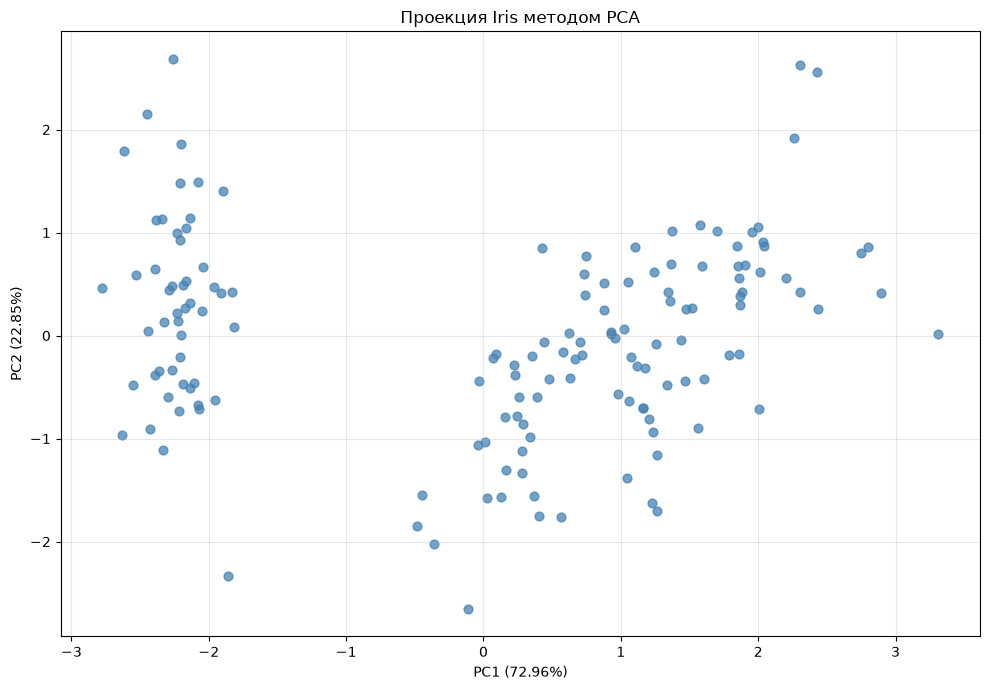

In [15]:
pc1 = X_pca[:, 0] # координаты наблюдений по первым двум компонентам
pc2 = X_pca[:, 1]

fig, ax = plt.subplots(figsize=(10, 7)) 
ax.scatter(pc1,pc2, color="steelblue",  s=40, alpha=0.75) # двумерная диаграмма рассеяния

ax.set_title("Проекция Iris методом PCA")
ax.set_xlabel(f"PC1 ({explained_variance[0] * 100:.2f}%)")
ax.set_ylabel( f"PC2 ({explained_variance[1] * 100:.2f}%)")
ax.grid(True, alpha=0.3)

plt.tight_layout()
fig.savefig(pics_save/ "3_1_pca_projection.png",dpi=300,bbox_inches="tight")
plt.show()

In [16]:
components_df = pd.DataFrame(pca.components_[:2].T,index=df.columns,columns=["PC1", "PC2"])# коэффициенты первых двух главных компонент и таблица взаимосвязи с исходными признаками

display(components_df.round(4))

,PC1,PC2
sepal length (cm),0.5211,0.3774
sepal width (cm),-0.2693,0.9233
petal length (cm),0.5804,0.0245
petal width (cm),0.5649,0.0669


# 7. Метод t-SNE

In [17]:
from sklearn.manifold import TSNE

tsne = TSNE(n_components=2,perplexity=30,learning_rate="auto",init="pca",random_state=42) #модель t-SNE с двумерным результатом

X_tsne = tsne.fit_transform(X_scaled) #стандартизированные данные в двумерном пространстве

print("Размерность после t-SNE:", X_tsne.shape)

Размерность после t-SNE: (150, 2)


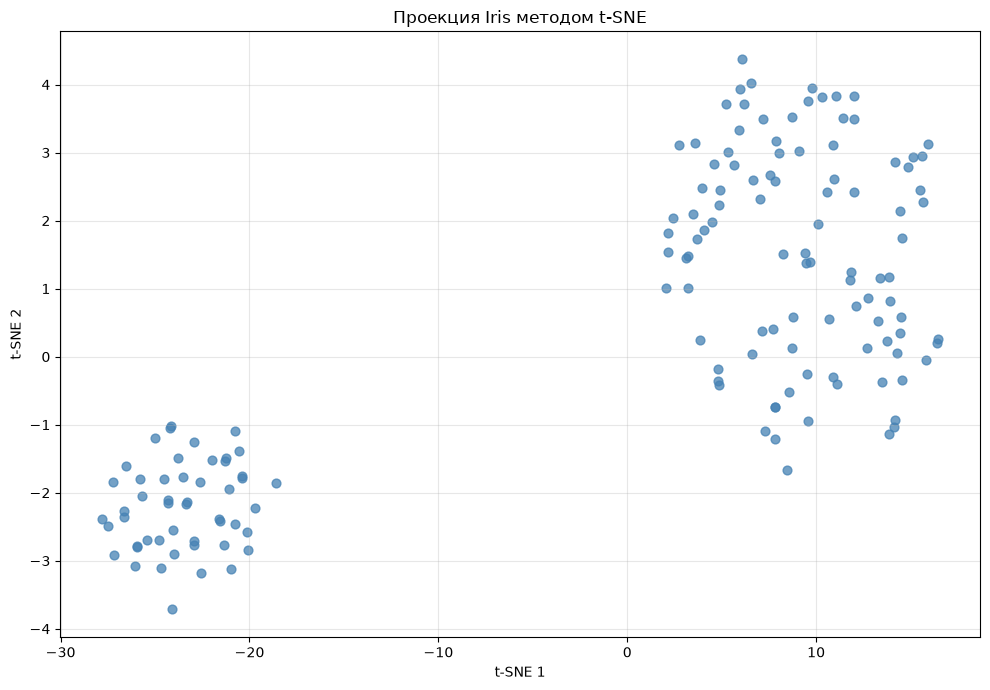

In [18]:
fig, ax = plt.subplots(figsize=(10, 7))

ax.scatter(X_tsne[:, 0],X_tsne[:, 1],color="steelblue",s=40,alpha=0.75)  # Отображание наблюдения в пространстве t-SNE
ax.set_title("Проекция Iris методом t-SNE")
ax.set_xlabel("t-SNE 1")
ax.set_ylabel("t-SNE 2")
ax.grid(True, alpha=0.3)

plt.tight_layout()

fig.savefig(pics_save / "4_1_tsne_projection.png",dpi=300,bbox_inches="tight")
plt.show()

# 8. Кластеризация K-means и итоговое сравнение

In [19]:
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score, adjusted_rand_score


k_values = [2, 3, 4] #  три варианта количества кластеров
kmeans_results = {} # результаты для последующих графиков
comparison = [] # показатели качества

for k in k_values:
    model = KMeans(n_clusters=k,random_state=42,n_init=10) # модель K-means
    labels = model.fit_predict(X_scaled) # кластеризация
    kmeans_results[k] = labels  # метки кластеров
    counts = pd.Series(labels).value_counts().sort_index() # размеры кластеров
    inertia = model.inertia_
    silhouette = silhouette_score(X_scaled, labels)
    ari = adjusted_rand_score(iris.target, labels)

    # Сохраняем показатели в таблицу
    comparison.append({"k": k,"Размеры кластеров": str(counts.tolist()),"Inertia": inertia,"Silhouette": silhouette,"ARI": ari})

    print(f"\nКоличество кластеров: {k}")
    print(counts)

comparison_df = pd.DataFrame(comparison)

display(comparison_df.round(3))


Количество кластеров: 2
0    100
1     50
Name: count, dtype: int64

Количество кластеров: 3
0    53
1    50
2    47
Name: count, dtype: int64

Количество кластеров: 4
0    47
1    53
2    28
3    22
Name: count, dtype: int64


,k,Размеры кластеров,Inertia,Silhouette,ARI
0,2,"[100, 50]",222.362,0.582,0.568
1,3,"[53, 50, 47]",139.820,0.460,0.620
2,4,"[47, 53, 28, 22]",114.093,0.387,0.473


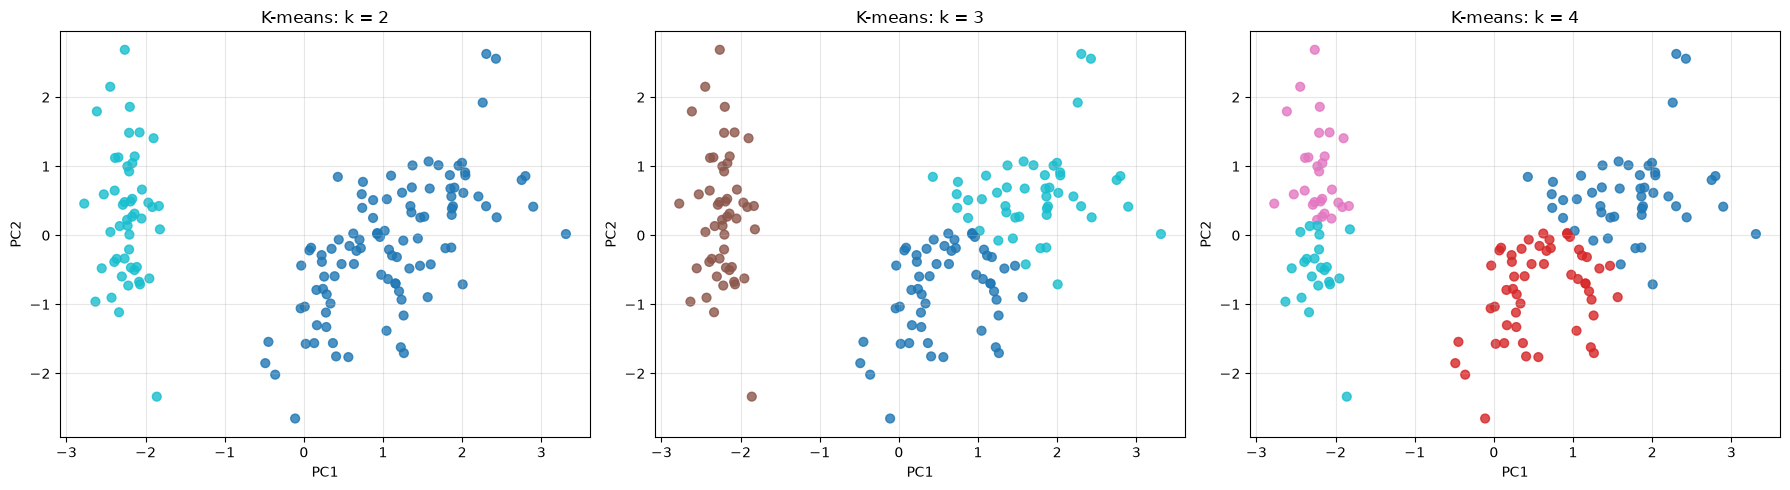

In [20]:
fig, axes = plt.subplots(1, 3, figsize=(18, 5))

for ax, k in zip(axes, k_values): # проекция для каждого значения k
    labels = kmeans_results[k] # Метки кластеров для текущего значения k
    scatter = ax.scatter(X_pca[:, 0], X_pca[:, 1],c=labels,  cmap="tab10", s=40,alpha=0.8) #наблюдения на плоскости первых двух компонент PCA
    ax.set_title(f"K-means: k = {k}")
    ax.set_xlabel("PC1")
    ax.set_ylabel("PC2")
    ax.grid(True, alpha=0.3)

plt.tight_layout()

fig.savefig(pics_save / "6_kmeans_comparison.png",dpi=300, bbox_inches="tight")

plt.show()

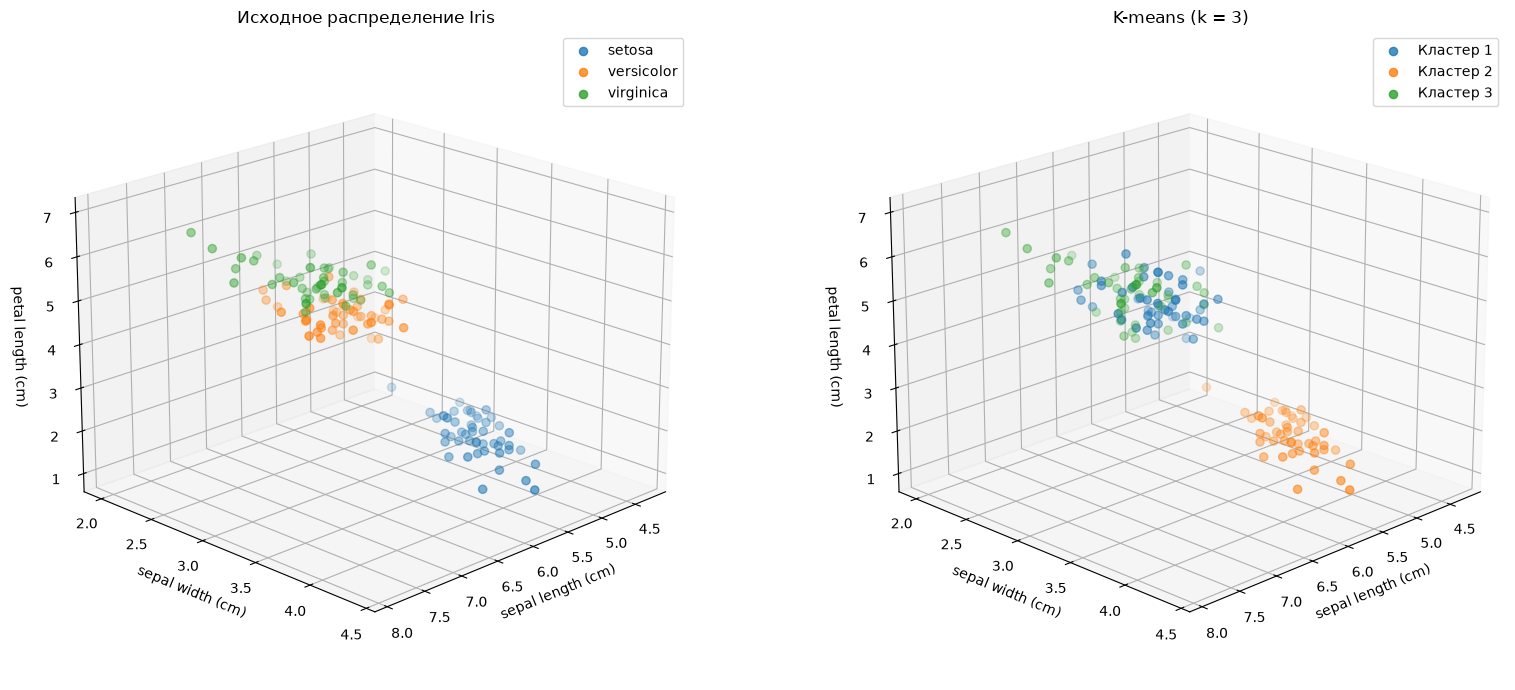

In [21]:
import numpy as np
import matplotlib.pyplot as plt

features = ["sepal length (cm)","sepal width (cm)","petal length (cm)"]

original_labels = iris.target
predicted_labels = kmeans_results[3] #  результаты K-means при трёх кластерах

fig = plt.figure(figsize=(17, 7))

ax1 = fig.add_subplot(121, projection="3d")
ax2 = fig.add_subplot(122, projection="3d")

for i in np.unique(original_labels): #Исходное распределение видов Iris
    mask = original_labels == i # Наблюдения текущего исходного класса
    ax1.scatter(df.loc[mask, features[0]], df.loc[mask, features[1]],df.loc[mask, features[2]],label=iris.target_names[i],  s=35, alpha=0.8 ) # точки выбранного класса

for i in np.unique(predicted_labels): # результаты кластеризации K-means
    mask = predicted_labels == i
    ax2.scatter(df.loc[mask, features[0]], df.loc[mask, features[1]], df.loc[mask, features[2]],label=f"Кластер {i + 1}",s=35,alpha=0.8)


for ax, title in zip([ax1, ax2],["Исходное распределение Iris", "K-means (k = 3)"]):
    ax.set_title(title)
    ax.set_xlabel(features[0])
    ax.set_ylabel(features[1])
    ax.set_zlabel(features[2])
    ax.view_init(elev=20, azim=45)
    ax.legend()

plt.tight_layout()
fig.savefig(pics_save / "7_3d_comparison.png",dpi=300,bbox_inches="tight")
plt.show()

In [22]:
# исходные виды с кластерами K-means при k = 3
comparison_table = pd.crosstab(pd.Series(iris.target_names[iris.target],name="Исходный вид"),pd.Series(kmeans_results[3],name="Кластер K-means"))

display(comparison_table)

Кластер K-means,0,1,2
Исходный вид,,,
setosa,0,50,0
versicolor,39,0,11
virginica,14,0,36
